<a href="https://colab.research.google.com/github/nicolastibata/MINE_4210_ADL_202620/blob/main/labs/Laboratorio_10/MINE_4210_ADL_202620_L10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

![Logo ADL](https://github.com/nicolastibata/MINE_4210_ADL_202620/blob/main/docs/logo.png?raw=true)

# **Laboratorio 10: VAE, GAN y modelos de difusión**
**Tutor: Nicolás Tibatá**

## **Tabla de Contenido**

[Contexto y objetivos](#scrollTo=R4YrUaE6udsU&line=14&uniqifier=1)<br>
[1. Comprensión de los datos](#scrollTo=VjA8zwzJvmeO&line=1&uniqifier=1)<br>
[2. Preparación de los datos](#scrollTo=kG8XHROzvuEH&line=1&uniqifier=1)<br>
[3. Modelamiento](#scrollTo=wCS6xYiU4YYs&line=1&uniqifier=1)<br>
[4. Evaluación](#scrollTo=nnCc67Uf5urd&line=1&uniqifier=1)<br>
[5. Espacio latente, difusión y pasos de muestreo](#scrollTo=52G-zC-3DTEj&line=1&uniqifier=1)<br>
[6. Preguntas](#scrollTo=8Z94PZwqmXeI&line=1&uniqifier=1)<br>

### **Contexto y Objetivos**

**Problema**
- Una empresa de reciclaje necesita **imágenes sintéticas** de residuos para ampliar un conjunto de datos pequeño (por ejemplo, para entrenar clasificadores como los del del lab 9). Quiere saber qué familia de modelos generativos produce imágenes más realistas y variadas con pocos datos y poco cómputo, y cómo medir esa calidad.

**Objetivos**
1. Construir y entrenar tres modelos generativos —un autocodificador variacional (**VAE**), una red generativa antagónica (**GAN**) y un modelo de **difusión**— sobre el mismo conjunto de imágenes, entendiendo qué optimiza cada uno.
2. Compararlos con métricas cuantitativas y visuales, y explorar su espacio latente y su proceso de generación.



**Datos**

Usaremos el dataset *Garbage Classification V2* (el mismo del Laboratorio 9), que puedes consultar [aquí](https://www.kaggle.com/datasets/sumn2u/garbage-classification-v2). Para mantener el costo bajo trabajaremos con **una sola clase** y con imágenes reducidas a **128×128 píxeles**.

In [ ]:
!pip install transformers diffusers accelerate kaggle -q

In [ ]:
import os
import glob
import time
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from torchvision.utils import make_grid
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from scipy.spatial.distance import pdist

from sklearn.model_selection import train_test_split
from transformers import AutoImageProcessor, AutoModel
from diffusers import UNet2DModel, DDPMScheduler, DDIMScheduler

from google.colab import userdata

In [ ]:
# Definimos nuestras semillas de reproducibilidad
SEED = 71
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", device)

Dispositivo: cuda


### **1. Comprensión de los datos**

Para entender cómo traemos los datos desde kaggle pueden revisar este [link](https://www.kaggle.com/discussions/general/51898#520673)

In [ ]:
os.environ["KAGGLE_KEY"] = userdata.get('KAGGLE_KEY')
os.environ["KAGGLE_USERNAME"] = userdata.get('KAGGLE_USERNAME')

!kaggle datasets download -d sumn2u/garbage-classification-v2

! unzip -q -o "garbage-classification-v2.zip" -d /content/garbage

Dataset URL: https://www.kaggle.com/datasets/sumn2u/garbage-classification-v2
License(s): MIT
100% 1.07G/1.07G [01:03<00:00, 18.0MB/s]



In [ ]:
# Recorremos las carpetas: la etiqueta de cada imagen es el nombre de su carpeta
CLASES = ['battery', 'biological', 'cardboard', 'clothes', 'glass',
          'metal', 'paper', 'plastic', 'shoes', 'trash']
EXTENSIONES = ('.jpg', '.jpeg', '.png')

Total de imágenes: 36777


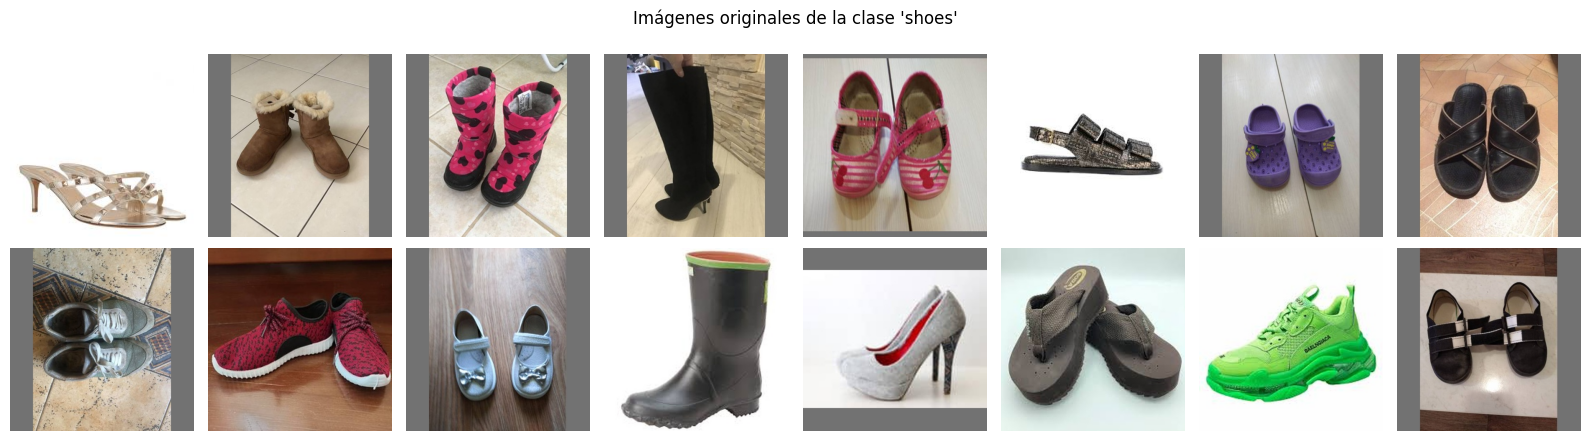

In [ ]:
rutas = [p for p in glob.glob('/content/garbage/**/*', recursive=True) if p.lower().endswith(EXTENSIONES)]
df = pd.DataFrame({'path': rutas})
df['label'] = df['path'].apply(lambda p: os.path.basename(os.path.dirname(p)).lower())
df = df[df['label'].isin(CLASES)].reset_index(drop=True)

print("Total de imágenes:", len(df))
df['label'].value_counts()

# Elegimos la clase con la que vamos a trabajar, en este caso usaremos shoes
CLASE_GEN = 'shoes'

fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for ax, ruta in zip(axes.ravel(), df[df['label'] == CLASE_GEN]['path'].sample(16, random_state=SEED)):
    ax.imshow(Image.open(ruta).convert('RGB'))
    ax.axis('off')
plt.suptitle(f"Imágenes originales de la clase '{CLASE_GEN}'")
plt.tight_layout()
plt.show()

> - Las imágenes originales son grandes y variadas (fondos, ángulos e iluminación distintos). Un modelo generativo aprende toda esa variabilidad.
> - Con pocas imágenes y poco cómputo no esperamos resultados fotorrealistas: el objetivo es comparar cómo se comporta cada familia de modelos.
Como vemos las imágenes tienen tamaños distintos, los modelos de visión esperan una entrada fija (224×224 en nuestro caso). Por lo tanto usamos el *image processor* de nuestro modelo para que se encargue de redimensionar y normalizar.


### **2. Preparación de los datos**

Reducimos las imágenes a 128×128 (recorte central y redimensionado), las escalamos al rango $[-1, 1]$ (coincide con la salida `tanh` de nuestras redes) y hacemos una partición entrenamiento/prueba.

In [ ]:
IMG = 128
N_MAX = 1500

In [ ]:
rutas_clase = df[df['label'] == CLASE_GEN]['path'].sample(frac=1, random_state=SEED).tolist()[:N_MAX]

def cargar(ruta):
    return np.array(ImageOps.fit(Image.open(ruta).convert('RGB'), (IMG, IMG), Image.LANCZOS))

imgs = np.stack([cargar(p) for p in rutas_clase])
print("Imágenes cargadas:", imgs.shape)

X_train, X_test = train_test_split(imgs, test_size=0.2, random_state=42, shuffle=True)

def a_tensor(x):
    return (torch.tensor(x).permute(0, 3, 1, 2).float() / 127.5 - 1.0)   # [0,255] -> [-1,1]

train_t, test_t = a_tensor(X_train), a_tensor(X_test)
print("Tamaño de datos de entrenamiento:", tuple(train_t.shape))
print("Tamaño de datos de prueba:", tuple(test_t.shape))

Imágenes cargadas: (1500, 128, 128, 3)
Tamaño de datos de entrenamiento: (1200, 3, 128, 128)
Tamaño de datos de prueba: (300, 3, 128, 128)


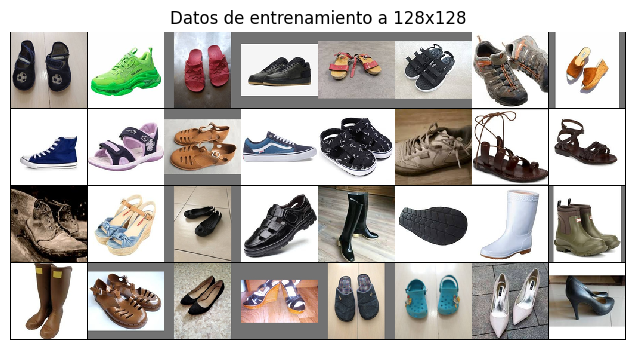

In [ ]:
BATCH = 64
loader = DataLoader(TensorDataset(train_t), batch_size=BATCH, shuffle=True, drop_last=True)

def mostrar(imgs, titulo='', nrow=8, ax=None):
    """Muestra una cuadrícula de imágenes en [-1, 1]."""
    grid = make_grid((imgs.detach().cpu().clamp(-1, 1) + 1) / 2, nrow=nrow, padding=1)
    if ax is None:
        plt.figure(figsize=(8, 8 * grid.shape[1] / grid.shape[2]))
        ax = plt.gca()
    ax.imshow(grid.permute(1, 2, 0).numpy(), interpolation='nearest')
    ax.set_title(titulo)
    ax.axis('off')

mostrar(train_t[:32], "Datos de entrenamiento a 128x128")
plt.show()

### **3. Modelamiento**

#### **3.1. Autocodificador variacional (VAE)**




Un VAE tiene un *encoder* que mapea cada imagen a una **distribución** en un espacio latente (media $\\mu$ y varianza $\\sigma^2$) y un *decoder* que reconstruye la imagen desde un punto muestreado. Se entrena maximizando una cota (ELBO) con dos términos (Reconstrucción y Divergencia KL).

In [ ]:
# Cada imagen (3x128x128 = 49152) lo disminuimos a un espacio latente de 128
LATENTE = 128

class VAE(nn.Module):
    def __init__(self, z=LATENTE):
        super().__init__()

        # ENCODER
        # Cada Conv2d(entrada, salida, kernel=4, stride=2, padding=1) reduce el tamaño espacial a la mitad y aumenta el número de canales.
        # Usamos LeakyReLU para ser un poco permisivos con valores negativos.
        self.enc = nn.Sequential(
            nn.Conv2d(3, 32, 4, 2, 1), nn.LeakyReLU(),      # 128 -> 64x64
            nn.Conv2d(32, 64, 4, 2, 1), nn.LeakyReLU(),     # 64
            nn.Conv2d(64, 128, 4, 2, 1), nn.LeakyReLU(),    # 32
            nn.Conv2d(128, 256, 4, 2, 1), nn.LeakyReLU(),   # 16
            nn.Conv2d(256, 256, 4, 2, 1), nn.LeakyReLU(),   # 8
            nn.Flatten())                                   # (256,4,4) -> vector de 4096

        # Número de características tras aplanar: 256 canales * 4 * 4
        feat = 256 * 4 * 4                                  # 4096

        self.mu = nn.Linear(feat, z)       # media de la distribución latente
        self.logvar = nn.Linear(feat, z)   # log de la varianza (así la varianza exp(logvar) siempre es > 0)

        # DECODER
        # Expande z (128) de vuelta a 4096 valores, que luego se reorganizan como un mapa de características de 256 canales y 4x4.
        self.fc = nn.Linear(z, feat)

        # ConvTranspose2d hace lo contrario que Conv2d con stride 2: duplica el tamaño espacial y reduce los canales hasta llegar a 3 (RGB).
        self.dec = nn.Sequential(
            nn.ConvTranspose2d(256, 256, 4, 2, 1), nn.LeakyReLU(),  # 4
            nn.ConvTranspose2d(256, 128, 4, 2, 1), nn.LeakyReLU(),  # 8
            nn.ConvTranspose2d(128, 64, 4, 2, 1), nn.LeakyReLU(),   # 16
            nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.LeakyReLU(),    # 32
            nn.ConvTranspose2d(32, 3, 4, 2, 1), nn.Tanh())          # 64 -> 128x128, salida en [-1, 1]
            # Tanh implica que las imágenes de entrada deben estar normalizadas a [-1, 1]

    def encode(self, x):
        # Traemos el mu y logvar de nuestro input del encoder que definimos
        h = self.enc(x)
        return self.mu(h), self.logvar(h)

    def reparametrizar(self, mu, logvar):
        # Reparametrización con: z = mu + sigma * epsilon, con epsilon ~ N(0, I).
        return mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)

    def decode(self, z):
        # z -> 4096 valores -> mapa (256, 4, 4) -> convoluciones transpuestas -> imagen
        # Tomamos la reconstrucción del decode
        return self.dec(self.fc(z).view(-1, 256, 4, 4))

    def forward(self, x):
        # Aqui recorremos el proceso: codificar -> muestrear z -> decodificar.
        # Se devuelven también mu y logvar porque la pérdida (KL) los necesita.
        mu, logvar = self.encode(x)
        return self.decode(self.reparametrizar(mu, logvar)), mu, logvar


def perdida_vae(x, x_rec, mu, logvar, beta=1.0):
    # Término de reconstrucción: error cuadrático sumado sobre todos los píxeles y dividido por el tamaño del batch
    rec = F.mse_loss(x_rec, x, reduction='sum') / x.size(0)

    # Divergencia KL
    # Regulariza el espacio latente para que se parezca a una normal estándar, lo que permite generar imágenes nuevas muestreando z ~ N(0, I).
    kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / x.size(0)

    # Trade off importante, beta controla el equilibrio.
    # Entonces beta alto -> espacio latente más ordenado pero reconstrucciones más borrosas; beta bajo lo contrario.
    return rec + beta * kl, rec, kl


def entrenar_vae(beta=1.0, epocas=40, z=LATENTE, lr=1e-3):
    modelo = VAE(z).to(device)                              # modelo en GPU/CPU
    opt = torch.optim.Adam(modelo.parameters(), lr=lr)      # optimizador Adam
    hist = {'rec': [], 'kl': []}                            # historial por época
    t0 = time.time()                                        # medimos el tiempo total

    for ep in range(epocas):
        modelo.train()                                      # modo entrenamiento
        r_ep = k_ep = n = 0                                 # acumuladores de la época

        for (x,) in loader:                                 # el loader entrega tuplas de un elemento (sin etiquetas)
            x = x.to(device)

            # Forward: reconstruimos y calculamos la pérdida
            x_rec, mu, logvar = modelo(x)
            loss, rec, kl = perdida_vae(x, x_rec, mu, logvar, beta)

            # Backward: limpiamos gradientes, calculamos y actualizamos pesos
            opt.zero_grad(); loss.backward(); opt.step()

            # Acumulamos pérdidas ponderadas por el tamaño del lote
            r_ep += rec.item() * x.size(0); k_ep += kl.item() * x.size(0); n += x.size(0)

        # Grudamos el promedio por imagen de la época
        hist['rec'].append(r_ep / n); hist['kl'].append(k_ep / n)

    # Devolvemos modelo entrenado, historial de pérdidas y segundos de entrenamiento
    return modelo, hist, time.time() - t0

VAE entrenado en 127 s | reconstrucción final: 1008.4 | KL final: 221.1


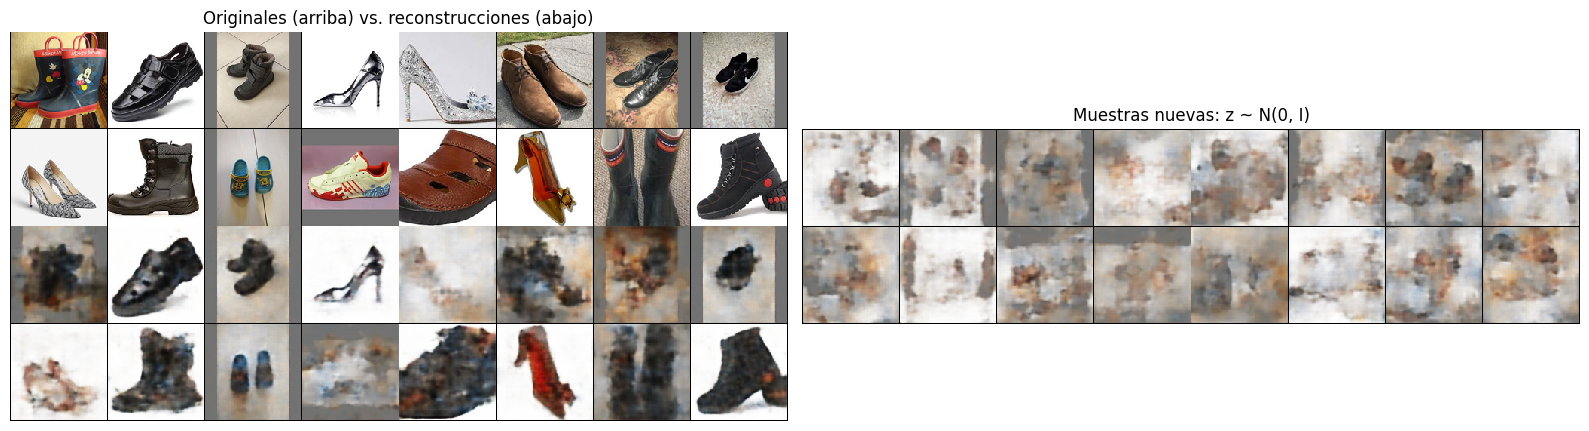

In [ ]:
vae, hist_vae, t_vae = entrenar_vae(beta=1.0, epocas=100)
print(f"VAE entrenado en {t_vae:.0f} s | reconstrucción final: {hist_vae['rec'][-1]:.1f} | KL final: {hist_vae['kl'][-1]:.1f}")

# Reconstrucciones de imágenes de prueba (arriba: originales, abajo: reconstruidas) y muestras nuevas
vae.eval()
with torch.no_grad():
    x = test_t[:16].to(device)
    mu, _ = vae.encode(x)
    rec = vae.decode(mu)
    torch.manual_seed(SEED)
    muestras_vae = vae.decode(torch.randn(16, LATENTE, device=device))

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
mostrar(torch.cat([x, rec]), "Originales (arriba) vs. reconstrucciones (abajo)", nrow=8, ax=axes[0])
mostrar(muestras_vae, "Muestras nuevas: z ~ N(0, I)", nrow=8, ax=axes[1])
plt.tight_layout()
plt.show()

#### **3.2 Red Generativa antagónica (GAN)**

Una GAN enfrenta a dos redes en un juego:
- El **generador** $G$ convierte ruido $z$ en imágenes e intenta engañar al discriminador.
- El **discriminador** $D$ aprende a distinguir imágenes reales de las generadas.

No hay una función de reconstrucción: el generador mejora porque el discriminador es cada vez más exigente. Usamos una arquitectura tipo **DCGAN** (convoluciones, *batch norm*) y una pequeña *suavización de etiquetas* (0.9 en lugar de 1.0 para las reales) que estabiliza el entrenamiento.

In [ ]:
Z_GAN = 100   # dimensión del ruido de entrada del generador

class Generador(nn.Module):
    def __init__(self, z=Z_GAN):
        super().__init__()
        # Ruido (z,1,1) -> imagen 3x128x128.
        # La primera capa convierte el vector en un mapa 4x4; cada capa siguiente duplica el tamaño espacial y reduce canales.
        self.net = nn.Sequential(
            nn.ConvTranspose2d(z, 512, 4, 1, 0, bias=False), nn.BatchNorm2d(512), nn.ReLU(True),    # 4x4
            nn.ConvTranspose2d(512, 256, 4, 2, 1, bias=False), nn.BatchNorm2d(256), nn.ReLU(True),  # 8x8
            nn.ConvTranspose2d(256, 128, 4, 2, 1, bias=False), nn.BatchNorm2d(128), nn.ReLU(True),  # 16x16
            nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False), nn.BatchNorm2d(64), nn.ReLU(True),    # 32x32
            nn.ConvTranspose2d(64, 32, 4, 2, 1, bias=False), nn.BatchNorm2d(32), nn.ReLU(True),     # 64x64
            nn.ConvTranspose2d(32, 3, 4, 2, 1), nn.Tanh())                                          # 128x128, salida en [-1, 1]

    def forward(self, z):
        # (batch, z) -> (batch, z, 1, 1) para poder usar convoluciones transpuestas
        return self.net(z.view(z.size(0), -1, 1, 1))


class Discriminador(nn.Module):
    def __init__(self):
        super().__init__()
        # Imagen 3x128x128 -> un único logit por imagen
        # Se baja hasta 4x4 para que la última convolución (kernel 4, sin padding) genere 1x1
        # No usamos BatchNorm en la primera capa
        self.net = nn.Sequential(
            nn.Conv2d(3, 32, 4, 2, 1), nn.LeakyReLU(0.2, True),                                       # 64x64
            nn.Conv2d(32, 64, 4, 2, 1, bias=False), nn.BatchNorm2d(64), nn.LeakyReLU(0.2, True),      # 32x32
            nn.Conv2d(64, 128, 4, 2, 1, bias=False), nn.BatchNorm2d(128), nn.LeakyReLU(0.2, True),    # 16x16
            nn.Conv2d(128, 256, 4, 2, 1, bias=False), nn.BatchNorm2d(256), nn.LeakyReLU(0.2, True),   # 8x8
            nn.Conv2d(256, 512, 4, 2, 1, bias=False), nn.BatchNorm2d(512), nn.LeakyReLU(0.2, True),   # 4x4
            nn.Conv2d(512, 1, 4, 1, 0))                                                               # 1x1 (logit)

    def forward(self, x):
        return self.net(x).view(-1)   # (batch,)


def iniciar_pesos(m):
    # Inicializamos los pesos de GAN ~ N(0, 0.02)
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(m.weight, 0.0, 0.02)
    elif isinstance(m, nn.BatchNorm2d):
        nn.init.normal_(m.weight, 1.0, 0.02); nn.init.zeros_(m.bias)


def entrenar_gan(epocas=200, lr=2e-4, suavizado=0.9, snapshots=(10, 50, 100, 200)):
    G, D = Generador().to(device), Discriminador().to(device) # Llamamos nuestros procesos a la GPU
    G.apply(iniciar_pesos); D.apply(iniciar_pesos)
    opt_g = torch.optim.Adam(G.parameters(), lr=lr, betas=(0.5, 0.999)) # Optimizador adam para generador
    opt_d = torch.optim.Adam(D.parameters(), lr=lr, betas=(0.5, 0.999)) # Optimizador adam para discriminador
    bce = nn.BCEWithLogitsLoss()
    z_fijo = torch.randn(16, Z_GAN, device=device)   # Definimos nuestro ruido fijo para ver la evolución
    hist, instantaneas = {'D': [], 'G': []}, {}      # Guardamos el historial
    t0 = time.time()
    for ep in range(1, epocas + 1):
        d_ep = g_ep = n = 0
        for (real,) in loader:
            real = real.to(device); b = real.size(0)
            # Discriminador: reales -> ~1 (con label smoothing), generadas -> 0
            fake = G(torch.randn(b, Z_GAN, device=device)).detach()
            loss_d = bce(D(real), torch.full((b,), suavizado, device=device)) + \
                     bce(D(fake), torch.zeros(b, device=device))
            opt_d.zero_grad(); loss_d.backward(); opt_d.step()
            # Generador: que D clasifique sus imágenes como reales
            loss_g = bce(D(G(torch.randn(b, Z_GAN, device=device))), torch.ones(b, device=device))
            opt_g.zero_grad(); loss_g.backward(); opt_g.step()
            d_ep += loss_d.item() * b; g_ep += loss_g.item() * b; n += b
        hist['D'].append(d_ep / n); hist['G'].append(g_ep / n)
        if ep in snapshots:
            G.eval()
            with torch.no_grad():
                instantaneas[ep] = G(z_fijo).cpu()
            G.train()
    return G, D, hist, time.time() - t0, instantaneas

GAN entrenada en 538 s


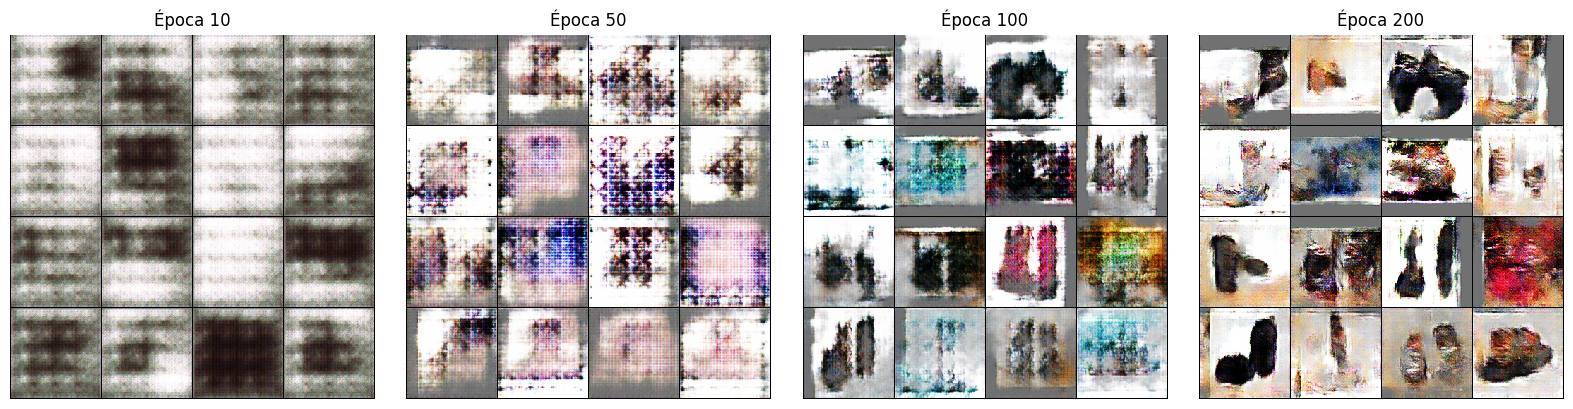

In [ ]:
G, D, hist_gan, t_gan, snaps_gan = entrenar_gan(epocas=200)
print(f"GAN entrenada en {t_gan:.0f} s")

# Evolución del generador con el mismo ruido fijo
fig, axes = plt.subplots(1, len(snaps_gan), figsize=(4 * len(snaps_gan), 4))
for ax, (ep, im) in zip(axes, snaps_gan.items()):
    mostrar(im, f"Época {ep}", nrow=4, ax=ax)
plt.tight_layout()
plt.show()

#### **3.3 Modelo de difusión (DDPM)**

Un modelo de difusión aprende a quitar ruido:
- **Proceso hacia adelante (fijo):** se agrega ruido gaussiano a la imagen poco a poco durante $T$ pasos hasta que queda ruido puro.
- **Proceso inverso (aprendido):** una red (aquí una **U-Net**) recibe una imagen ruidosa y el paso $t$ y **predice el ruido** que se agregó. Se entrena con un simple error cuadrático medio, lo que lo hace mucho más estable que una GAN.
- **Generación:** se parte de ruido puro y se aplica la red de forma iterativa para eliminar ruido paso a paso. Es lento, porque requiere muchas evaluaciones de la red.

Usamos la librería `diffusers` para la U-Net y el planificador de ruido, con una U-Net pequeña.


> Sin embargo la arquitectura U net crea demasiadas activaciones a las imágenes, bajaremos su resolución a 64x64, para no quedar sin memoria

In [ ]:
# limpiamos nuestro cache para usar la mayor cantidad de espacio posible
import gc

# Borramos modelos, optimizadores y tensores grandes que hayan quedado
for v in ['unet', 'opt', 'scaler', 'G', 'D', 'vae', 'out', 'x', 'loss', 'pred',
          'x_ruidosa', 'ruido', 't', 'z', 'rec', 'muestras_vae']:
    globals().pop(v, None)

# Limpiamos el traceback del error
import sys
sys.last_traceback = sys.last_value = sys.last_type = None

gc.collect()
torch.cuda.empty_cache()
print(f"En uso: {torch.cuda.memory_allocated()/1e9:.2f} GB | reservada: {torch.cuda.memory_reserved()/1e9:.2f} GB")

En uso: 0.90 GB | reservada: 9.70 GB


In [ ]:
IMG = 64

# Reducimos los tensores de 128x128 a 64x64
train_64 = F.interpolate(train_t, size=IMG, mode='bilinear', antialias=True, align_corners=False)
loader = DataLoader(TensorDataset(train_64), batch_size=32, shuffle=True, drop_last=True)

In [ ]:
IMG = 64           # tamaño de las imágenes (alto = ancho)
T_TRAIN = 1000     # número de pasos del proceso de ruido

def crear_unet():
    # U-Net que recibe una imagen ruidosa y el paso t, y predice el ruido añadido.
    # Con 3 niveles la resolución baja 64 -> 32 -> 16.
    # La atención solo va en el nivel de menor resolución (16x16 = 256 posiciones), por el bajo costo de memoria y limites computacionales de colab
    unet = UNet2DModel(
        sample_size=IMG,                          # resolución de entrada/salida
        in_channels=3, out_channels=3,            # RGB -> ruido RGB
        layers_per_block=2,                       # bloques residuales por nivel
        block_out_channels=(64, 128, 256),        # canales en cada nivel
        down_block_types=(
            "DownBlock2D",                        # 64x64 -> 32x32
            "DownBlock2D",                        # 32x32 -> 16x16
            "AttnDownBlock2D",                    # 16x16 (con atención)
        ),
        up_block_types=(
            "AttnUpBlock2D",                      # 16x16 -> 32x32 (con atención)
            "UpBlock2D",                          # 32x32 -> 64x64
            "UpBlock2D",                          # 64x64
        ),
    ).to(device)
    # Gradient checkpointing nos ayuda ahorrando memoria, recalculando las activaciones en el backward
    unet.enable_gradient_checkpointing()
    return unet

# Scheduler que define el proceso hacia adelante (cómo se añade ruido según los pasos)
sched_train = DDPMScheduler(num_train_timesteps=T_TRAIN)

def entrenar_difusion(epocas=100, lr=2e-4):
    unet = crear_unet()
    opt = torch.optim.AdamW(unet.parameters(), lr=lr)
    # GradScaler evita que los gradientes en fp16 se anulen por underflow
    scaler = torch.amp.GradScaler('cuda')
    hist, t0 = [], time.time()

    for ep in range(epocas):
        unet.train()
        l_ep = n = 0                                            # acumuladores de la época

        for (x,) in loader:
            x = x.to(device)                                    # imágenes limpias en [-1, 1]
            ruido = torch.randn_like(x)                         # ruido gaussiano objetivo
            # Un paso t aleatorio por imagen: la red aprende a quitar ruido a todos los niveles
            t = torch.randint(0, T_TRAIN, (x.size(0),), device=device)
            x_ruidosa = sched_train.add_noise(x, ruido, t)      # proceso hacia adelante

            # autocast: operaciones en fp16 (consumimos menos memoria y es más rápido)
            with torch.autocast('cuda', dtype=torch.float16):
                pred = unet(x_ruidosa, t).sample                # la red predice el ruido
            loss = F.mse_loss(pred.float(), ruido)              # pérdida en fp32 por estabilidad

            opt.zero_grad(set_to_none=True)                     # libera memoria de gradientes
            scaler.scale(loss).backward()                       # backward con pérdida escalada
            scaler.unscale_(opt)                                # desescala para recortar gradientes
            torch.nn.utils.clip_grad_norm_(unet.parameters(), 1.0)   # estabiliza el entrenamiento
            scaler.step(opt)                                    # actualiza pesos
            scaler.update()                                     # ajusta el factor de escala

            l_ep += loss.item() * x.size(0); n += x.size(0)

        hist.append(l_ep / n)                                   # pérdida media de la época

    return unet, hist, time.time() - t0

In [ ]:
unet, hist_dif, t_dif = entrenar_difusion(epocas=100)
print(f"Difusión entrenada en {t_dif:.0f} s | U-Net con {sum(p.numel() for p in unet.parameters())/1e6:.1f}M parámetros")

Difusión entrenada en 1261 s | U-Net con 15.7M parámetros


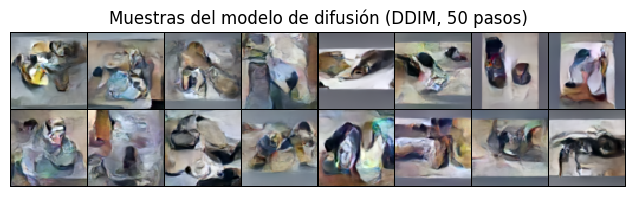

In [ ]:
@torch.no_grad()
def muestrear_difusion(n, pasos=50, seed=SEED, batch=100):
    """Genera n imágenes con DDIM (determinista) usando `pasos` evaluaciones de la U-Net."""
    unet.eval()
    sch = DDIMScheduler(num_train_timesteps=T_TRAIN)
    sch.set_timesteps(pasos)
    torch.manual_seed(seed)
    salidas = []
    for i in range(0, n, batch):
        x = torch.randn(min(batch, n - i), 3, IMG, IMG, device=device)
        for t in sch.timesteps:
            x = sch.step(unet(x, t).sample, t, x).prev_sample
        salidas.append(x.clamp(-1, 1))
    return torch.cat(salidas)

mostrar(muestrear_difusion(16, pasos=50), "Muestras del modelo de difusión (DDIM, 50 pasos)")
plt.show()

### **4. Evaluación**

Evaluar un modelo generativo es difícil ya que no hay una "etiqueta correcta". Usamos tres miradas complementarias:
- **Visual:** ¿las imágenes parecen reales?
- **Distancia de Fréchet (FD):** compara la distribución de las imágenes reales y las generadas en el espacio de características de una red preentrenada (usamos **ResNet-50** que fue la misma del Laboratorio 9). Menor es mejor.
- **Diversidad:** distancia promedio entre pares de imágenes generadas, relativa a la de imágenes reales. Un valor muy por debajo de 1 sugiere *mode collapse* (el modelo genera siempre cosas parecidas).


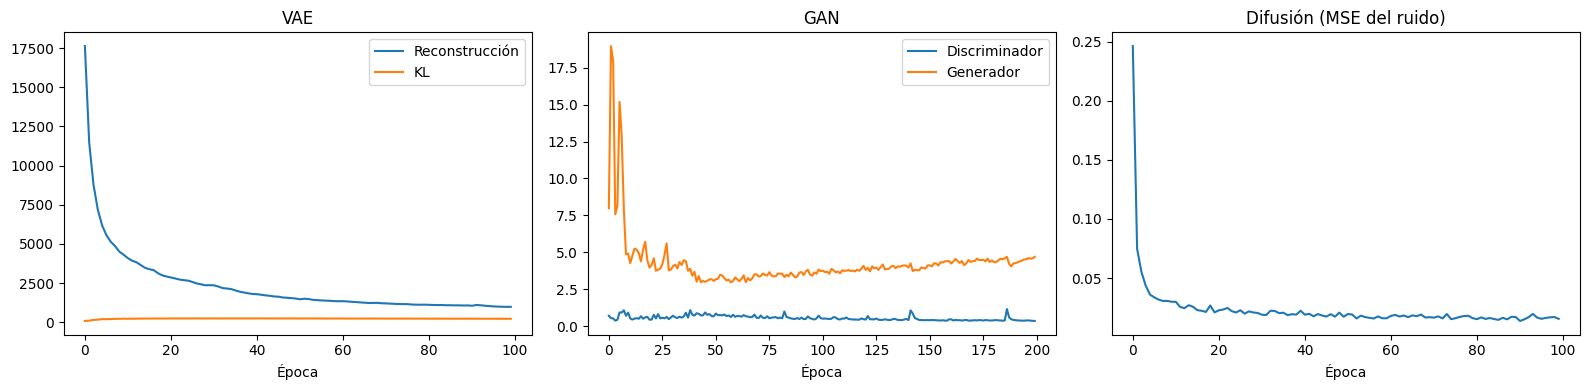

In [ ]:
# Veamos nuestras curvas de entrenamiento
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(hist_vae['rec'], label='Reconstrucción'); axes[0].plot(hist_vae['kl'], label='KL')
axes[0].set_title("VAE"); axes[0].set_xlabel("Época"); axes[0].legend()
axes[1].plot(hist_gan['D'], label='Discriminador'); axes[1].plot(hist_gan['G'], label='Generador')
axes[1].set_title("GAN"); axes[1].set_xlabel("Época"); axes[1].legend()
axes[2].plot(hist_dif); axes[2].set_title("Difusión (MSE del ruido)"); axes[2].set_xlabel("Época")
plt.tight_layout()
plt.show()

In [ ]:
# Extractor de características para FD (ResNet-50)
RESNET_NAME = "microsoft/resnet-50"
proc_rn = AutoImageProcessor.from_pretrained(RESNET_NAME)
resnet = AutoModel.from_pretrained(RESNET_NAME).to(device).eval()
MEDIA = torch.tensor(proc_rn.image_mean).view(1, 3, 1, 1)
DESV = torch.tensor(proc_rn.image_std).view(1, 3, 1, 1)

@torch.no_grad()
def caracteristicas(imgs, batch=100):
    feats = []
    for i in range(0, len(imgs), batch):
        x = (imgs[i:i + batch].clamp(-1, 1) + 1) / 2
        x = F.interpolate(x, size=224, mode='bilinear', align_corners=False)
        x = ((x - MEDIA.to(x.device)) / DESV.to(x.device)).to(device)
        feats.append(resnet(pixel_values=x).pooler_output.flatten(1).cpu())
    return torch.cat(feats).numpy().astype(np.float64)

def _raiz_psd(M):
    w, V = np.linalg.eigh(M)
    return (V * np.sqrt(np.clip(w, 0, None))) @ V.T

def distancia_frechet(f_real, f_fake):
    mu1, mu2 = f_real.mean(0), f_fake.mean(0)
    s1, s2 = np.cov(f_real, rowvar=False), np.cov(f_fake, rowvar=False)
    r1 = _raiz_psd(s1)
    A = r1 @ s2 @ r1                                           # tr(sqrt(s1 s2)) = tr(sqrt(A)), A simétrica
    tr_raiz = np.sqrt(np.clip(np.linalg.eigvalsh((A + A.T) / 2), 0, None)).sum()
    return float(((mu1 - mu2) ** 2).sum() + np.trace(s1) + np.trace(s2) - 2 * tr_raiz)

def sincronizar():
    if device == "cuda":
        torch.cuda.synchronize()

N_EVAL = len(test_t)
generados, t_muestreo = {}, {}

sincronizar(); t0 = time.time()
vae.eval()
with torch.no_grad():
    torch.manual_seed(SEED)
    generados["VAE"] = vae.decode(torch.randn(N_EVAL, LATENTE, device=device)).cpu()
sincronizar(); t_muestreo["VAE"] = time.time() - t0

sincronizar(); t0 = time.time()
G.eval()
with torch.no_grad():
    torch.manual_seed(SEED)
    generados["GAN"] = G(torch.randn(N_EVAL, Z_GAN, device=device)).cpu()
sincronizar(); t_muestreo["GAN"] = time.time() - t0

sincronizar(); t0 = time.time()
generados["Difusión (DDIM 50)"] = muestrear_difusion(N_EVAL, pasos=50).cpu()
sincronizar(); t_muestreo["Difusión (DDIM 50)"] = time.time() - t0

Loading weights:   0%|          | 0/318 [00:00<?, ?it/s]

[transformers] ResNetModel LOAD REPORT from: microsoft/resnet-50
Key                 | Status     |  | 
--------------------+------------+--+-
classifier.1.bias   | UNEXPECTED |  | 
classifier.1.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


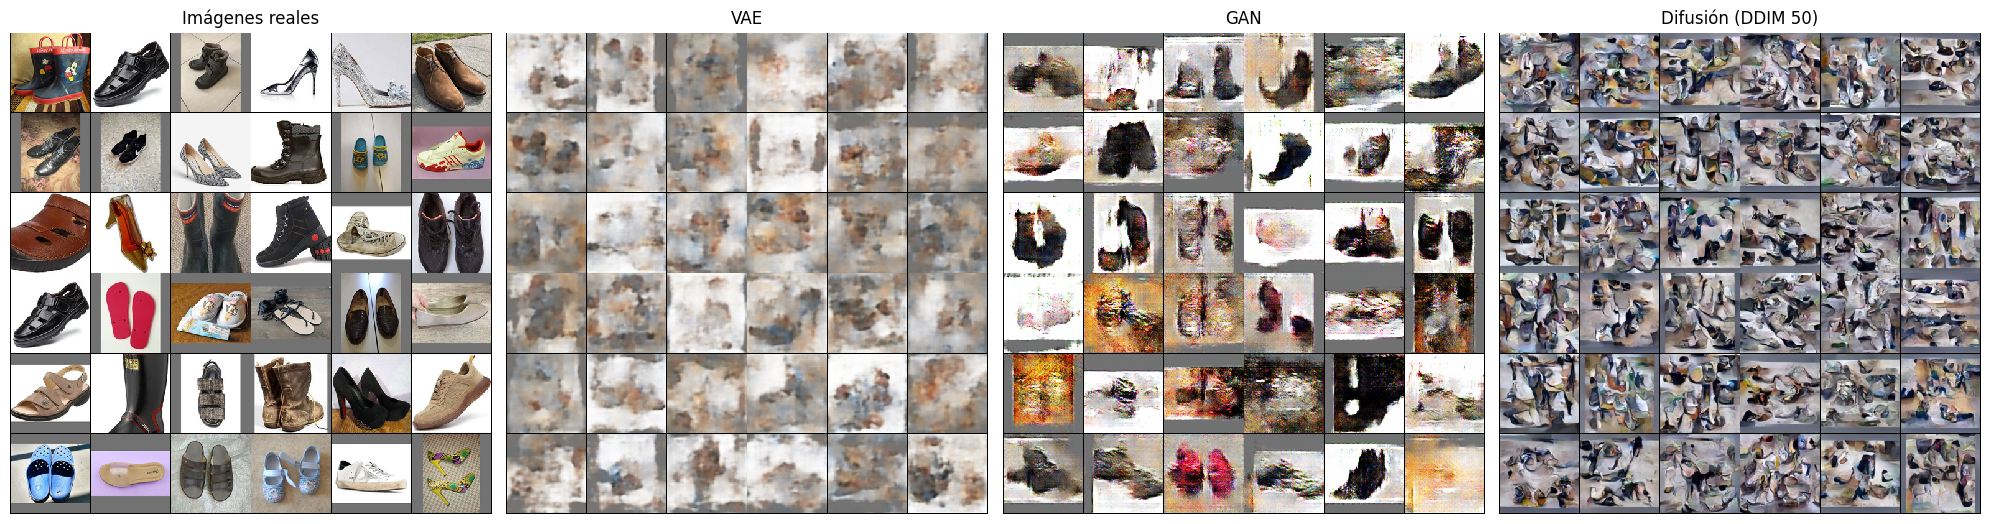

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5.5))
mostrar(test_t[:36], "Imágenes reales", nrow=6, ax=axes[0])
for ax, (nombre, im) in zip(axes[1:], generados.items()):
    mostrar(im[:36], nombre, nrow=6, ax=ax)
plt.tight_layout()
plt.show()

In [ ]:
# Veamos nuestras métricas cuantitativas
f_real = caracteristicas(train_t)
f_test = caracteristicas(test_t)
div_real = pdist(f_test).mean()

n_params = {
    "VAE": sum(p.numel() for p in vae.parameters()),
    "GAN": sum(p.numel() for p in G.parameters()) + sum(p.numel() for p in D.parameters()),
    "Difusión (DDIM 50)": sum(p.numel() for p in unet.parameters()),
}
t_train = {"VAE": t_vae, "GAN": t_gan, "Difusión (DDIM 50)": t_dif}

filas = [{"modelo": "Real (prueba)", "FD": distancia_frechet(f_real, f_test), "diversidad_rel": 1.0,
          "parametros_M": np.nan, "seg_entrenamiento": np.nan, "seg_muestreo": np.nan}]
for nombre, im in generados.items():
    f = caracteristicas(im)
    filas.append({"modelo": nombre, "FD": distancia_frechet(f_real, f), "diversidad_rel": pdist(f).mean() / div_real,
                  "parametros_M": n_params[nombre] / 1e6, "seg_entrenamiento": t_train[nombre],
                  "seg_muestreo": t_muestreo[nombre]})

tabla = pd.DataFrame(filas).set_index("modelo")
tabla.round(3)

,FD,diversidad_rel,parametros_M,seg_entrenamiento,seg_muestreo
modelo,,,,,
Real (prueba),6.316,1.000,NaN,NaN,NaN
VAE,45.379,0.650,5.055,127.227,0.100
GAN,38.261,0.806,6.405,538.263,0.107
Difusión (DDIM 50),49.754,0.968,15.725,1260.792,436.117


> - La fila **Real (prueba)** es un piso de referencia: la FD entre dos conjuntos de imágenes *reales* del mismo tamaño. Ningún modelo debería (ni podría) bajar de ese valor; comparar contra él ayuda a interpretar el sesgo por pocas muestras.
> - Algo importante a notar es que el tiempo de **entrenamiento** con el de **muestreo** no siempre van de la mano.


### **5. Espacio latente, difusión y pasos de muestreo**

#### **5.1. Interpolación en el espacio latente**

Si el espacio latente está bien organizado, moverse suavemente entre dos puntos debería producir imágenes intermedias **plausibles**. Lo contrastamos con simplemente mezclar píxeles (primera fila).

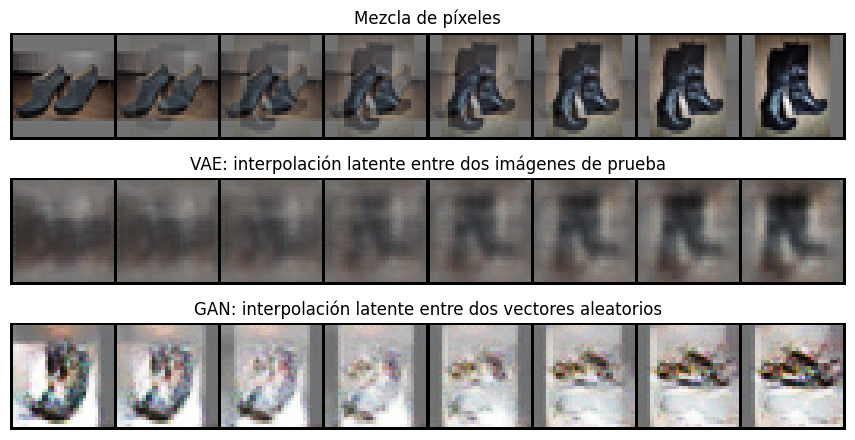

In [ ]:
pasos_interp = 8
alphas = torch.linspace(0, 1, pasos_interp, device=device).view(-1, 1)

with torch.no_grad():
    a, b = test_t[0:1].to(device), test_t[1:2].to(device)
    # Mezcla directa de píxeles
    fila_pix = (1 - alphas.view(-1, 1, 1, 1)) * a + alphas.view(-1, 1, 1, 1) * b
    # Interpolación en el espacio latente del VAE
    mu_a, _ = vae.encode(a); mu_b, _ = vae.encode(b)
    fila_vae = vae.decode((1 - alphas) * mu_a + alphas * mu_b)
    # Interpolación en el espacio latente de la GAN
    torch.manual_seed(SEED)
    za, zb = torch.randn(1, Z_GAN, device=device), torch.randn(1, Z_GAN, device=device)
    fila_gan = G((1 - alphas) * za + alphas * zb)

fig, axes = plt.subplots(3, 1, figsize=(12, 4.5))
mostrar(fila_pix, "Mezcla de píxeles", nrow=pasos_interp, ax=axes[0])
mostrar(fila_vae, "VAE: interpolación latente entre dos imágenes de prueba", nrow=pasos_interp, ax=axes[1])
mostrar(fila_gan, "GAN: interpolación latente entre dos vectores aleatorios", nrow=pasos_interp, ax=axes[2])
plt.tight_layout()
plt.show()


> El VAE tiene un *encoder*, así que puede **codificar imágenes reales** y moverse entre ellas. La GAN no tiene encoder: solo podemos interpolar entre vectores de ruido.

#### **5.2. El proceso de difusión: para adelante y para atrás**

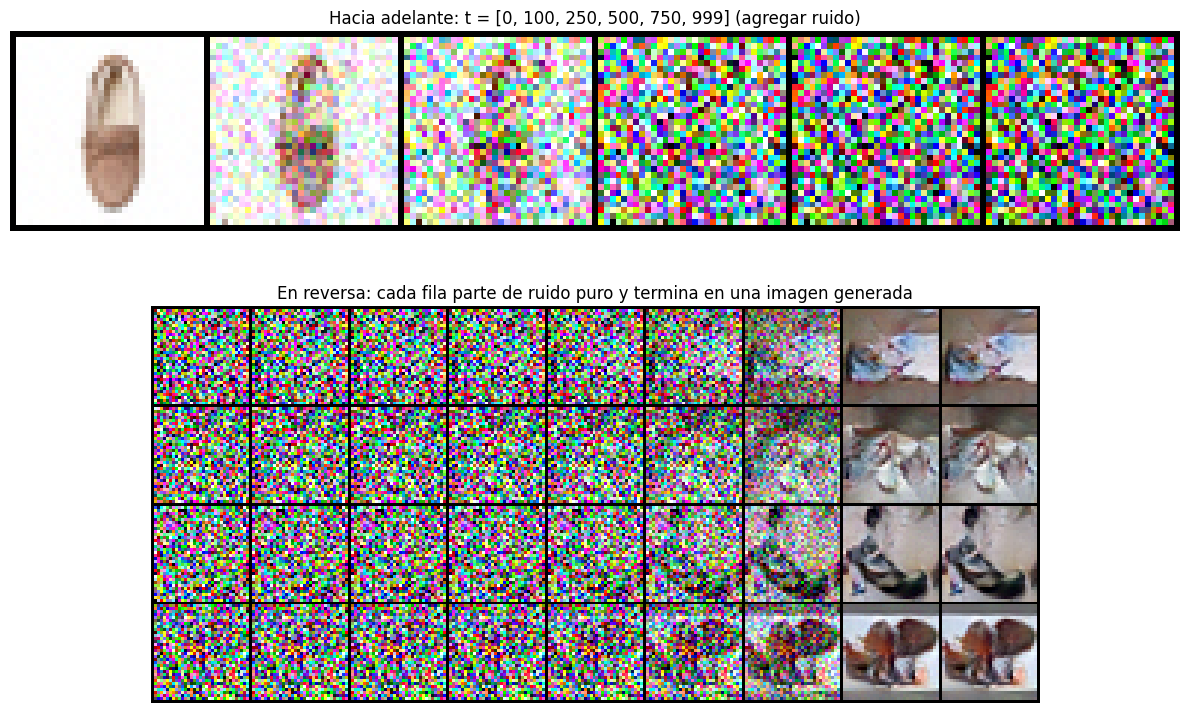

In [ ]:
# Proceso hacia adelante: la imagen se va convirtiendo en ruido
img0 = test_t[2:3].to(device)
ts = [0, 100, 250, 500, 750, 999]
torch.manual_seed(SEED)
ruido = torch.randn_like(img0)
adelante = torch.cat([sched_train.add_noise(img0, ruido, torch.tensor([t], device=device)) for t in ts])

# Proceso inverso: de ruido puro a imagen (guardamos algunos estados intermedios)
@torch.no_grad()
def trayectoria_difusion(n=4, pasos=50, n_snap=8, seed=SEED):
    unet.eval()
    sch = DDIMScheduler(num_train_timesteps=T_TRAIN)
    sch.set_timesteps(pasos)
    torch.manual_seed(seed)
    x = torch.randn(n, 3, IMG, IMG, device=device)
    marcas = set(np.linspace(0, pasos - 1, n_snap).astype(int).tolist())
    snaps = []
    for i, t in enumerate(sch.timesteps):
        if i in marcas:
            snaps.append(x.clamp(-1, 1).cpu())
        x = sch.step(unet(x, t).sample, t, x).prev_sample
    snaps.append(x.clamp(-1, 1).cpu())
    return torch.stack(snaps, dim=1).flatten(0, 1)   # (n * (n_snap+1), 3, H, W), una fila por imagen

traj = trayectoria_difusion(n=4, pasos=50, n_snap=8)

fig, axes = plt.subplots(2, 1, figsize=(12, 8))
mostrar(adelante, f"Hacia adelante: t = {ts} (agregar ruido)", nrow=len(ts), ax=axes[0])
mostrar(traj, "En reversa: cada fila parte de ruido puro y termina en una imagen generada", nrow=9, ax=axes[1])
plt.tight_layout()
plt.show()

#### **5.3. Pasos de muestreo vs. calidad**

El costo de la difusión está en el muestreo: cada imagen requiere varias evaluaciones de la U-Net. Medimos cuánto mejora la calidad al aumentar los pasos de DDIM.

            seg_muestreo      FD
pasos_DDIM                      
5                  2.067  32.518
10                 4.010  28.108
25                10.105  25.909
50                20.970  28.684
100               40.226  33.202


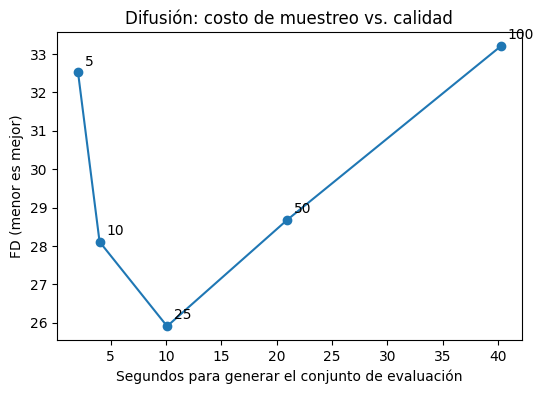

In [ ]:
filas_pasos = []
for pasos in [5, 10, 25, 50, 100]:
    sincronizar(); t0 = time.time()
    im = muestrear_difusion(N_EVAL, pasos=pasos).cpu()
    sincronizar(); dt = time.time() - t0
    filas_pasos.append({"pasos_DDIM": pasos, "seg_muestreo": dt, "FD": distancia_frechet(f_real, caracteristicas(im))})

tabla_pasos = pd.DataFrame(filas_pasos).set_index("pasos_DDIM")
print(tabla_pasos.round(3))

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(tabla_pasos["seg_muestreo"], tabla_pasos["FD"], marker='o')
for pasos, r in tabla_pasos.iterrows():
    ax.annotate(str(pasos), (r["seg_muestreo"], r["FD"]), textcoords="offset points", xytext=(5, 5))
ax.set_xlabel("Segundos para generar el conjunto de evaluación")
ax.set_ylabel("FD (menor es mejor)")
ax.set_title("Difusión: costo de muestreo vs. calidad")
plt.show()

**Cerremos con unas conclusiones:**

- **VAE:** optimiza una cota de la verosimilitud (reconstrucción + KL). Su espacio latente es continuo y organizado, y tiene encoder; a cambio, las imágenes suelen salir **borrosas** porque el error cuadrático promedia posibilidades y la regularización KL limita el detalle.
- **GAN:** genera en **un solo paso** y suele producir imágenes más nítidas, pero el entrenamiento es un juego inestable. Sus pérdidas **no indican calidad** (que baje la pérdida del generador puede significar que el discriminador se debilitó) y puede sufrir *mode collapse*.
- **Difusión:** se entrena con un objetivo simple y estable (predecir ruido) y cubre bien la diversidad, pero el muestreo es **iterativo y lento**. Con una U-Net pequeña, pocas imágenes y pocas épocas, aquí no alcanza su potencial; su fuerte viene de mayor variabilidad y escala.
- La FD resume la similitud entre distribuciones en el espacio de características de una red preentrenada, pero **no detecta memorización** (copiar imágenes de entrenamiento daría una FD excelente) y con pocas muestras es ruidosa. Por eso se combina con inspección visual y con la diversidad.


### **6. Preguntas**

1. **VAE: reconstrucción vs. regularización.** Entrena el VAE con `beta` = 0.1, 1 y 4 (`entrenar_vae(beta=...)`). Para cada valor reporta el error de reconstrucción y el KL finales, la FD, la diversidad y observa las muestras y las reconstrucciones. Explica el compromiso que controla `beta` y por qué las muestras de un VAE tienden a verse borrosas. Propón una modificación (por ejemplo, otra dimensión latente `z`, más épocas o una arquitectura más profunda), aplícala y compara la FD y la diversidad.

2. **GAN: diagnóstico del entrenamiento.** Analiza las curvas de pérdida del discriminador y del generador y las imágenes de la evolución por épocas. ¿Converge el entrenamiento? ¿Hay señales de *mode collapse* (revisa la diversidad relativa)? ¿Por qué la pérdida no sirve como medida de calidad? Cambia un elemento (tasa de aprendizaje, suavizado de etiquetas, número de épocas o arquitectura), reentrena y compara la FD y la diversidad.